# 03 - Transfer learning (ResNet-18 and MobileNetV2)

**Owner:** Rachana (Part C)

This notebook evaluates two pretrained ImageNet architectures on EuroSAT (`resnet18` and `mobilenet_v2`), comparing a **frozen backbone** (`lr = 0.001`, only the new 10-class head learns) against **full fine-tuning** (`lr = 0.0001`, all layers learn).

All runs use the shared training function `train()` from `src/train.py`, which enforces the fixed 70/15/15 split in `data/splits.csv`, ImageNet normalisation, training-only rotations and flips, batch size 64, Adam optimiser, up to 20 epochs, and best-epoch selection on the validation set.

In [1]:
from pathlib import Path
import json
import os
import sys

# Help CUDA reuse memory blocks on Windows. This does not change model behaviour.
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')

# Make imports work whether Jupyter starts in the repo root or in the notebooks folder.
project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import pandas as pd
import torch

from src.train import BATCH_SIZE, MAX_EPOCHS, TRANSFER, build_model, train
from src.utils import DATA_DIR, FIGURES_DIR, METRICS_CSV, MODELS_DIR, SPLITS_CSV, get_device

device = get_device()
print('Device:', device)
print('GPU:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'not available')

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
# Initial Lap 1 transfer-learning configurations (seed 0 on the full training split).
MODEL_NAMES = [
    'resnet18_frozen',
    'resnet18_full',
    'mobilenet_v2_frozen',
    'mobilenet_v2_full',
]
INITIAL_SEED = 0
FRACTION = 1.0

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
assert SPLITS_CSV.is_file(), f'Missing fixed split: {SPLITS_CSV}'
assert (DATA_DIR / 'eurosat/2750').is_dir(), 'Download EuroSAT using check_setup.py --download'

# Inspect each configuration's learning rate and parameter counts from src/train.py and src/models.py.
config_rows = []
for model_name in MODEL_NAMES:
    backbone, freeze = TRANSFER[model_name]
    model, lr = build_model(model_name)
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    config_rows.append({
        'model': model_name,
        'backbone': backbone,
        'freeze_backbone': freeze,
        'learning_rate': lr,
        'batch_size': BATCH_SIZE,
        'max_epochs': MAX_EPOCHS,
        'trainable_params': trainable_params,
        'total_params': total_params,
    })
    del model

config_df = pd.DataFrame(config_rows)
display(config_df)

,model,backbone,freeze_backbone,learning_rate,batch_size,max_epochs,trainable_params,total_params
0,resnet18_frozen,resnet18,True,0.0010,64,20,5130,11181642
1,resnet18_full,resnet18,False,0.0001,64,20,11181642,11181642
2,mobilenet_v2_frozen,mobilenet_v2,True,0.0010,64,20,12810,2236682
3,mobilenet_v2_full,mobilenet_v2,False,0.0001,64,20,2236682,2236682


## Seed 0 transfer-learning runs

Each configuration is trained for `MAX_EPOCHS = 20` epochs with `seed = 0` and `fraction = 1.0` through the shared `train()` function in `src/train.py`. For every run, `train()` selects the checkpoint from the epoch with the highest validation accuracy, evaluates the test set once, saves the best weights in `models/`, and updates `results/metrics.csv`.

In [3]:
import math

seed0_runs = {}
history_path = FIGURES_DIR / 'transfer_seed0_histories.json'

existing_metrics_df = (
    pd.read_csv(METRICS_CSV)
    if METRICS_CSV.is_file() and METRICS_CSV.stat().st_size > 0
    else pd.DataFrame(columns=['model', 'fraction', 'seed', 'accuracy', 'macro_f1'])
)
saved_seed0_histories = {}
if history_path.is_file():
    if history_path.stat().st_size == 0:
        raise RuntimeError(f'Seed-0 history file is empty/corrupt: {history_path}')
    with open(history_path, 'r', encoding='utf-8') as f:
        saved_seed0_histories = json.load(f)

any_seed0_trained = False

for model_name in MODEL_NAMES:
    # 1. Check metrics CSV row for (model_name, FRACTION, INITIAL_SEED)
    row_matches = existing_metrics_df[
        (existing_metrics_df['model'] == model_name)
        & (pd.to_numeric(existing_metrics_df['fraction'], errors='coerce') == FRACTION)
        & (pd.to_numeric(existing_metrics_df['seed'], errors='coerce') == INITIAL_SEED)
    ]
    if len(row_matches) > 1:
        raise RuntimeError(
            f'Duplicate rows ({len(row_matches)}) in {METRICS_CSV} for '
            f'({model_name}, fraction={FRACTION}, seed={INITIAL_SEED}).'
        )
    has_csv = len(row_matches) == 1
    csv_acc, csv_f1 = None, None
    if has_csv:
        csv_acc = float(pd.to_numeric(row_matches['accuracy'].iloc[0], errors='coerce'))
        csv_f1 = float(pd.to_numeric(row_matches['macro_f1'].iloc[0], errors='coerce'))
        if not (
            math.isfinite(csv_acc)
            and math.isfinite(csv_f1)
            and 0.0 < csv_acc <= 1.0
            and 0.0 < csv_f1 <= 1.0
        ):
            raise RuntimeError(
                f'Invalid accuracy/macro_f1 in {METRICS_CSV} for '
                f'({model_name}, fraction={FRACTION}, seed={INITIAL_SEED}): acc={csv_acc}, f1={csv_f1}'
            )

    # 2. Check model checkpoint in models/
    ckpt_path = MODELS_DIR / f'{model_name}_frac{FRACTION:g}_seed{INITIAL_SEED}.pth'
    if ckpt_path.exists() and ckpt_path.stat().st_size == 0:
        raise RuntimeError(f'Checkpoint file is empty (0 bytes): {ckpt_path}')
    has_ckpt = ckpt_path.is_file() and ckpt_path.stat().st_size > 0

    # 3. Check seed-0 training history in transfer_seed0_histories.json
    has_hist = model_name in saved_seed0_histories
    if has_hist:
        entry = saved_seed0_histories[model_name]
        required_keys = {'best_epoch', 'val_accuracy', 'accuracy', 'macro_f1', 'seconds_per_epoch', 'history'}
        if not isinstance(entry, dict) or not required_keys.issubset(entry.keys()):
            raise RuntimeError(
                f'Invalid or incomplete history entry for {model_name} in {history_path}.'
            )
        hist = entry['history']
        for hkey in ('train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'):
            vals = hist.get(hkey, []) if isinstance(hist, dict) else []
            if len(vals) != MAX_EPOCHS or not all(math.isfinite(float(v)) for v in vals):
                raise RuntimeError(
                    f'Invalid {hkey} history for {model_name} in {history_path} '
                    f'(expected {MAX_EPOCHS} finite epoch values).'
                )
        if has_csv and not (
            math.isclose(float(entry['accuracy']), csv_acc, abs_tol=1e-6)
            and math.isclose(float(entry['macro_f1']), csv_f1, abs_tol=1e-6)
        ):
            raise RuntimeError(
                f'Metric mismatch between {METRICS_CSV} and {history_path} for '
                f'({model_name}, fraction={FRACTION}, seed={INITIAL_SEED}).'
            )

    if has_csv and has_ckpt and has_hist:
        entry = saved_seed0_histories[model_name]
        seed0_runs[model_name] = {
            'model': model_name,
            'fraction': FRACTION,
            'seed': INITIAL_SEED,
            'best_epoch': int(entry['best_epoch']),
            'val_accuracy': float(entry['val_accuracy']),
            'accuracy': float(entry['accuracy']),
            'macro_f1': float(entry['macro_f1']),
            'seconds_per_epoch': float(entry['seconds_per_epoch']),
            'history': entry['history'],
        }
        print(
            f'Skip {model_name} (fraction={FRACTION}, seed={INITIAL_SEED}): '
            f'verified in {METRICS_CSV.name}, {ckpt_path.name}, and {history_path.name}'
        )
        continue

    if has_csv or has_ckpt or has_hist:
        raise RuntimeError(
            f'Inconsistent artifacts for ({model_name}, fraction={FRACTION}, seed={INITIAL_SEED}): '
            f'metrics_csv={has_csv}, checkpoint={has_ckpt} ({ckpt_path.name}), '
            f'seed0_history={has_hist} ({history_path.name}). Refusing to overwrite partial results.'
        )

    print('=' * 72)
    print(f'Starting {model_name} (fraction={FRACTION}, seed={INITIAL_SEED}, epochs={MAX_EPOCHS})')
    print('=' * 72)
    result = train(model_name, fraction=FRACTION, seed=INITIAL_SEED, epochs=MAX_EPOCHS)
    seed0_runs[model_name] = result
    any_seed0_trained = True
    existing_metrics_df = pd.read_csv(METRICS_CSV)
    print(
        f"Summary -> {model_name} | best val epoch: {result['best_epoch']} "
        f"| best val acc: {result['val_accuracy']:.4f} "
        f"| test acc: {result['accuracy']:.4f} "
        f"| test macro-F1: {result['macro_f1']:.4f} "
        f"| {result['seconds_per_epoch']:.1f} s/epoch\n"
    )

if any_seed0_trained or not history_path.is_file():
    with open(history_path, 'w', encoding='utf-8') as f:
        json.dump(
            {
                name: {
                    'best_epoch': res['best_epoch'],
                    'val_accuracy': res['val_accuracy'],
                    'accuracy': res['accuracy'],
                    'macro_f1': res['macro_f1'],
                    'seconds_per_epoch': res['seconds_per_epoch'],
                    'history': res['history'],
                }
                for name, res in seed0_runs.items()
            },
            f,
            indent=2,
        )
    print('Saved seed 0 histories to', history_path)
else:
    print('All seed 0 runs already complete and verified; preserved existing', history_path)

Starting resnet18_frozen (fraction=1.0, seed=0, epochs=20)
Reading 27000 images into memory (one time, about 20 seconds)...
resnet18_frozen | fraction 1 | seed 0 | epoch 01/20 | train loss 0.8825, acc 0.739 | val loss 0.6013, acc 0.811 | 4.4 s
resnet18_frozen | fraction 1 | seed 0 | epoch 02/20 | train loss 0.5408, acc 0.835 | val loss 0.5701, acc 0.824 | 3.0 s
resnet18_frozen | fraction 1 | seed 0 | epoch 03/20 | train loss 0.5017, acc 0.840 | val loss 0.5316, acc 0.835 | 2.8 s
resnet18_frozen | fraction 1 | seed 0 | epoch 04/20 | train loss 0.4770, acc 0.846 | val loss 0.4872, acc 0.844 | 2.9 s
resnet18_frozen | fraction 1 | seed 0 | epoch 05/20 | train loss 0.4600, acc 0.850 | val loss 0.4844, acc 0.841 | 2.8 s
resnet18_frozen | fraction 1 | seed 0 | epoch 06/20 | train loss 0.4578, acc 0.849 | val loss 0.4710, acc 0.849 | 2.7 s
resnet18_frozen | fraction 1 | seed 0 | epoch 07/20 | train loss 0.4559, acc 0.848 | val loss 0.4668, acc 0.851 | 2.7 s
resnet18_frozen | fraction 1 | seed 

## Seed 0 comparison table and learning curves

The table below summarises the validation and test scores for all four transfer-learning settings at seed 0. The plots compare training and validation loss and accuracy across the 20 epochs.

,model,seed,best_epoch,best_val_accuracy,test_accuracy,test_macro_f1,seconds_per_epoch
0,resnet18_frozen,0,16,0.857037,0.868642,0.863935,3.185456
1,resnet18_full,0,20,0.977531,0.980988,0.980332,7.883621
2,mobilenet_v2_frozen,0,13,0.874568,0.877531,0.872573,5.358403
3,mobilenet_v2_full,0,17,0.981235,0.982716,0.981770,14.958303


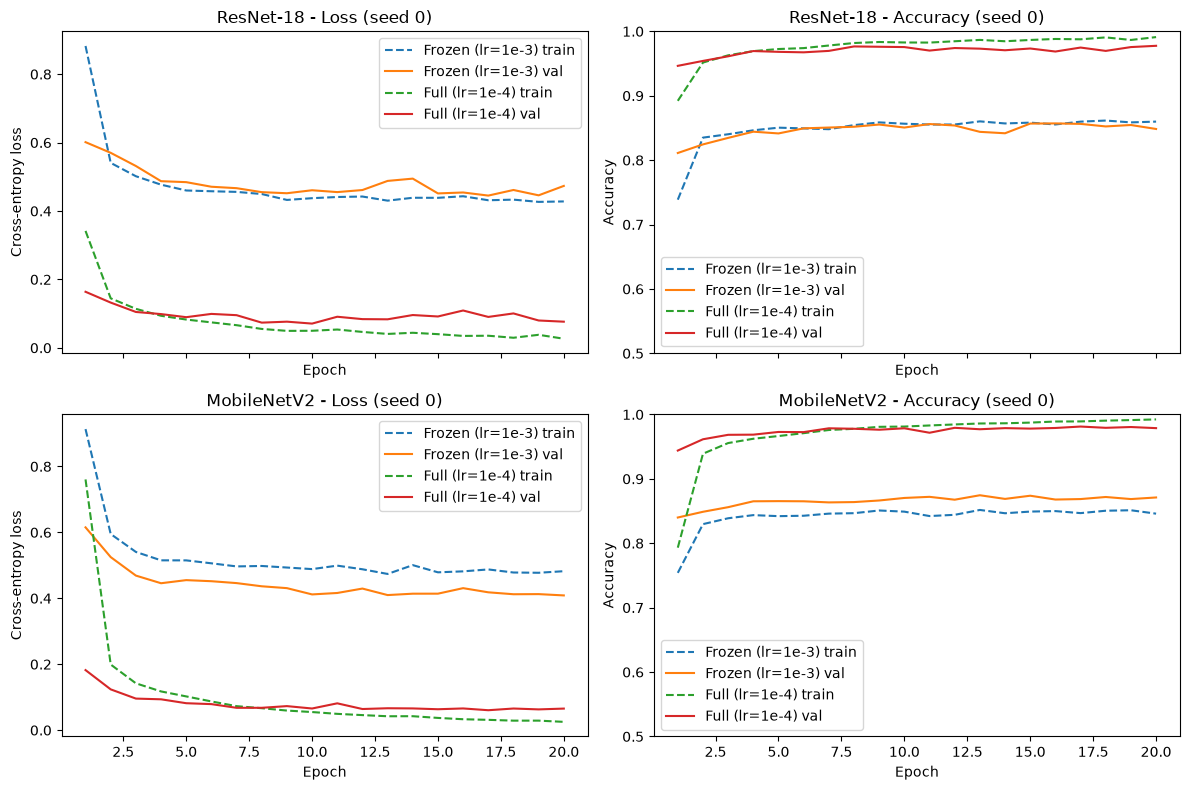

Saved learning curves to D:\3rd Year\Deep Learning and CNN\Project\Eyes in the sky\Eyes-in-the-Sky\results\figures\transfer_learning_curves_seed0.png


In [4]:
summary_rows = [
    {
        'model': model_name,
        'seed': result['seed'],
        'best_epoch': result['best_epoch'],
        'best_val_accuracy': result['val_accuracy'],
        'test_accuracy': result['accuracy'],
        'test_macro_f1': result['macro_f1'],
        'seconds_per_epoch': result['seconds_per_epoch'],
    }
    for model_name, result in seed0_runs.items()
]
seed0_df = pd.DataFrame(summary_rows)
display(seed0_df)

epochs_range = range(1, MAX_EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

plot_groups = [
    ('ResNet-18', ['resnet18_frozen', 'resnet18_full'], 0),
    ('MobileNetV2', ['mobilenet_v2_frozen', 'mobilenet_v2_full'], 1),
]

for arch_title, names, row_idx in plot_groups:
    loss_ax, acc_ax = axes[row_idx, 0], axes[row_idx, 1]
    for name in names:
        hist = seed0_runs[name]['history']
        label_prefix = 'Frozen (lr=1e-3)' if name.endswith('_frozen') else 'Full (lr=1e-4)'
        loss_ax.plot(epochs_range, hist['train_loss'], linestyle='--', label=f'{label_prefix} train')
        loss_ax.plot(epochs_range, hist['val_loss'], linestyle='-', label=f'{label_prefix} val')
        acc_ax.plot(epochs_range, hist['train_accuracy'], linestyle='--', label=f'{label_prefix} train')
        acc_ax.plot(epochs_range, hist['val_accuracy'], linestyle='-', label=f'{label_prefix} val')

    loss_ax.set_title(f'{arch_title} - Loss (seed 0)')
    loss_ax.set_xlabel('Epoch')
    loss_ax.set_ylabel('Cross-entropy loss')
    loss_ax.legend()

    acc_ax.set_title(f'{arch_title} - Accuracy (seed 0)')
    acc_ax.set_xlabel('Epoch')
    acc_ax.set_ylabel('Accuracy')
    acc_ax.set_ylim(0.5, 1.0)
    acc_ax.legend()

fig.tight_layout()
curves_path = FIGURES_DIR / 'transfer_learning_curves_seed0.png'
fig.savefig(curves_path, dpi=160)
plt.show()
print('Saved learning curves to', curves_path)

## Lap 2: Three-seed transfer-learning sweep (seeds 0, 1, 2)

This section completes the 3-seed protocol (`SEEDS = [0, 1, 2]`) for all four transfer-learning configurations at `fraction = 1.0`. Before starting a run, the code checks `results/metrics.csv` and skips the `(model, fraction, seed)` combination if it already has valid, non-null `accuracy` and `macro_f1` scores (such as the four seed 0 runs completed in Lap 1). Each missing run uses `train()` from `src/train.py` and appends its single test evaluation row to `results/metrics.csv`.

In [3]:
import math

SEEDS = [0, 1, 2]
all_seeds_history_path = FIGURES_DIR / 'transfer_all_seeds_histories.json'

saved_all_seeds_runs = {}
if all_seeds_history_path.is_file():
    if all_seeds_history_path.stat().st_size == 0:
        raise RuntimeError(f'All-seeds history file is empty/corrupt: {all_seeds_history_path}')
    with open(all_seeds_history_path, 'r', encoding='utf-8') as f:
        all_seeds_payload = json.load(f)
    if not isinstance(all_seeds_payload, dict) or 'runs' not in all_seeds_payload:
        raise RuntimeError(f"Missing 'runs' key in {all_seeds_history_path}")
    saved_all_seeds_runs = all_seeds_payload['runs']

for model_name in MODEL_NAMES:
    for seed in SEEDS:
        existing_df = (
            pd.read_csv(METRICS_CSV)
            if METRICS_CSV.is_file() and METRICS_CSV.stat().st_size > 0
            else pd.DataFrame(columns=['model', 'fraction', 'seed', 'accuracy', 'macro_f1'])
        )

        # 1. Check metrics CSV row for (model_name, FRACTION, seed)
        row_matches = existing_df[
            (existing_df['model'] == model_name)
            & (pd.to_numeric(existing_df['fraction'], errors='coerce') == FRACTION)
            & (pd.to_numeric(existing_df['seed'], errors='coerce') == seed)
        ]
        if len(row_matches) > 1:
            raise RuntimeError(
                f'Duplicate rows ({len(row_matches)}) in {METRICS_CSV} for '
                f'({model_name}, fraction={FRACTION}, seed={seed}).'
            )
        has_csv = len(row_matches) == 1
        csv_acc, csv_f1 = None, None
        if has_csv:
            csv_acc = float(pd.to_numeric(row_matches['accuracy'].iloc[0], errors='coerce'))
            csv_f1 = float(pd.to_numeric(row_matches['macro_f1'].iloc[0], errors='coerce'))
            if not (
                math.isfinite(csv_acc)
                and math.isfinite(csv_f1)
                and 0.0 < csv_acc <= 1.0
                and 0.0 < csv_f1 <= 1.0
            ):
                raise RuntimeError(
                    f'Invalid accuracy/macro_f1 in {METRICS_CSV} for '
                    f'({model_name}, fraction={FRACTION}, seed={seed}): acc={csv_acc}, f1={csv_f1}'
                )

        # 2. Check model checkpoint in models/
        ckpt_path = MODELS_DIR / f'{model_name}_frac{FRACTION:g}_seed{seed}.pth'
        if ckpt_path.exists() and ckpt_path.stat().st_size == 0:
            raise RuntimeError(f'Checkpoint file is empty (0 bytes): {ckpt_path}')
        has_ckpt = ckpt_path.is_file() and ckpt_path.stat().st_size > 0

        # 3. Check training history in transfer_all_seeds_histories.json
        seed_key = f'seed_{seed}'
        model_runs = saved_all_seeds_runs.get(model_name, {}) if isinstance(saved_all_seeds_runs, dict) else {}
        has_hist = isinstance(model_runs, dict) and seed_key in model_runs
        if has_hist:
            run_entry = model_runs[seed_key]
            required_keys = {'best_epoch', 'val_accuracy', 'accuracy', 'macro_f1', 'seconds_per_epoch', 'history'}
            if not isinstance(run_entry, dict) or not required_keys.issubset(run_entry.keys()):
                raise RuntimeError(
                    f'Invalid or incomplete history entry for ({model_name}, {seed_key}) in {all_seeds_history_path}.'
                )
            hist = run_entry['history']
            for hkey in ('train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch_seconds'):
                vals = hist.get(hkey, []) if isinstance(hist, dict) else []
                if len(vals) != MAX_EPOCHS or not all(math.isfinite(float(v)) for v in vals):
                    raise RuntimeError(
                        f'Invalid {hkey} history for ({model_name}, {seed_key}) in {all_seeds_history_path} '
                        f'(expected {MAX_EPOCHS} finite epoch values).'
                    )
            if has_csv and not (
                math.isclose(float(run_entry['accuracy']), csv_acc, abs_tol=1e-6)
                and math.isclose(float(run_entry['macro_f1']), csv_f1, abs_tol=1e-6)
            ):
                raise RuntimeError(
                    f'Metric mismatch between {METRICS_CSV} and {all_seeds_history_path} for '
                    f'({model_name}, fraction={FRACTION}, seed={seed}).'
                )

        if has_csv and has_ckpt and has_hist:
            print(
                f'Skip {model_name} (fraction={FRACTION}, seed={seed}): '
                f'verified in {METRICS_CSV.name}, {ckpt_path.name}, and {all_seeds_history_path.name}'
            )
            continue

        if has_csv or has_ckpt or has_hist:
            raise RuntimeError(
                f'Inconsistent artifacts for ({model_name}, fraction={FRACTION}, seed={seed}): '
                f'metrics_csv={has_csv}, checkpoint={has_ckpt} ({ckpt_path.name}), '
                f'history={has_hist} ({all_seeds_history_path.name}). Refusing to overwrite partial results.'
            )

        print('=' * 72)
        print(f'Starting {model_name} (fraction={FRACTION}, seed={seed}, epochs={MAX_EPOCHS})')
        print('=' * 72)
        result = train(model_name, fraction=FRACTION, seed=seed, epochs=MAX_EPOCHS)
        print(
            f"Summary -> {model_name} (seed {seed}) | best val epoch: {result['best_epoch']} "
            f"| best val acc: {result['val_accuracy']:.4f} "
            f"| test acc: {result['accuracy']:.4f} "
            f"| test macro-F1: {result['macro_f1']:.4f} "
            f"| {result['seconds_per_epoch']:.1f} s/epoch\n"
        )

Skip resnet18_frozen (fraction=1.0, seed=0): already in metrics.csv
Skip resnet18_frozen (fraction=1.0, seed=1): already in metrics.csv
Skip resnet18_frozen (fraction=1.0, seed=2): already in metrics.csv
Skip resnet18_full (fraction=1.0, seed=0): already in metrics.csv
Skip resnet18_full (fraction=1.0, seed=1): already in metrics.csv
Skip resnet18_full (fraction=1.0, seed=2): already in metrics.csv
Skip mobilenet_v2_frozen (fraction=1.0, seed=0): already in metrics.csv
Skip mobilenet_v2_frozen (fraction=1.0, seed=1): already in metrics.csv
Skip mobilenet_v2_frozen (fraction=1.0, seed=2): already in metrics.csv
Skip mobilenet_v2_full (fraction=1.0, seed=0): already in metrics.csv
Skip mobilenet_v2_full (fraction=1.0, seed=1): already in metrics.csv
Starting mobilenet_v2_full (fraction=1.0, seed=2, epochs=20)
Reading 27000 images into memory (one time, about 20 seconds)...
mobilenet_v2_full | fraction 1 | seed 2 | epoch 01/20 | train loss 0.7535, acc 0.798 | val loss 0.1843, acc 0.947 | 

### Lap 2 Execution History & Recovered Training Logs (`transfer_all_seeds_histories.json`)

**Execution & Provenance Note:**
1. **Seven Lap 2 runs recovered from `task-594.log`:** When Lap 2 (`seeds 1 and 2` at `fraction = 1.0`) was first launched via the background script `run_lap2_cell.py` (`task-594`), seven of the eight missing experiments completed all 20 epochs, saved their best-validation-epoch checkpoints (`.pth`) to `models/`, and wrote their full-precision `float64` test evaluation rows to `results/metrics.csv` (`resnet18_frozen` seeds 1 & 2, `resnet18_full` seeds 1 & 2, `mobilenet_v2_frozen` seeds 1 & 2, and `mobilenet_v2_full` seed 1). The eighth experiment (`mobilenet_v2_full`, seed 2) was interrupted during Epoch 07/20 due to a Windows display driver reset before completion.
2. **Eighth Lap 2 run recorded in `cell-08-run-lap2` above:** When `cell-08-run-lap2` was subsequently executed in the native Python 3.12.10 Jupyter kernel, the skip-check verified that the first 11 `(model, fraction=1.0, seed)` combinations were already present in `results/metrics.csv` (printing `Skip ...: already in metrics.csv`) and executed only the remaining `mobilenet_v2_full` (`seed = 2`) experiment to completion.
3. **Historical JSON & Precision Distinction (`results/figures/transfer_all_seeds_histories.json`):**
   - **`results/figures/transfer_seed0_histories.json` is preserved unchanged** and holds the **4 seed-0 runs** captured directly in memory from `train()`'s return dictionary at full `float64` precision.
   - **`results/figures/transfer_all_seeds_histories.json`** consolidates all **12 transfer-learning runs** (`4 models × 3 seeds`), preserving the verbatim stdout log lines and explicitly distinguishing numeric precision by source:
     - **Seed 0 (4 runs):** Exact `float64` per-epoch histories, `best_val_accuracy`, `test_accuracy`, `test_macro_f1`, and `seconds_per_epoch` from `transfer_seed0_histories.json` (plus per-epoch wall-clock seconds `.1f` from `cell-04-run-seed0` stdout).
     - **Seeds 1 & 2 (7 runs from `task-594.log` + 1 run from `cell-08-run-lap2` stdout):** Per-epoch `train_loss`, `val_loss`, and `best_val_accuracy` are recorded at `src/train.py`'s printed 4-decimal precision (`:.4f`); per-epoch `train_accuracy` and `val_accuracy` are recorded at 3-decimal precision (`:.3f`); `seconds_per_epoch` and `epoch_seconds` are recorded at 1-decimal precision (`:.1f`); and final `test_accuracy` and `test_macro_f1` are paired with their exact `float64` values from `results/metrics.csv`.

In [4]:
# Verify and display all 12 transfer-learning runs from results/figures/transfer_all_seeds_histories.json
# and cross-check every run against results/metrics.csv.
all_seeds_history_path = FIGURES_DIR / 'transfer_all_seeds_histories.json'
with open(all_seeds_history_path, 'r', encoding='utf-8') as f:
    all_seeds_data = json.load(f)

metrics_check_df = pd.read_csv(METRICS_CSV)

all_runs_rows = []
for model_name in MODEL_NAMES:
    for seed in SEEDS:
        run_entry = all_seeds_data['runs'][model_name][f'seed_{seed}']
        hist = run_entry['history']

        # Verify all 20 epochs are present and non-empty
        assert len(hist['train_loss']) == MAX_EPOCHS
        assert len(hist['train_accuracy']) == MAX_EPOCHS
        assert len(hist['val_loss']) == MAX_EPOCHS
        assert len(hist['val_accuracy']) == MAX_EPOCHS
        assert len(hist['epoch_seconds']) == MAX_EPOCHS

        # Cross-check against results/metrics.csv
        csv_match = metrics_check_df[
            (metrics_check_df['model'] == model_name)
            & (pd.to_numeric(metrics_check_df['fraction'], errors='coerce') == FRACTION)
            & (pd.to_numeric(metrics_check_df['seed'], errors='coerce') == seed)
        ]
        assert len(csv_match) == 1, f'Missing or duplicate row in metrics.csv for {model_name} seed {seed}'
        csv_acc = float(csv_match['accuracy'].iloc[0])
        csv_f1 = float(csv_match['macro_f1'].iloc[0])

        assert abs(csv_acc - run_entry['accuracy']) == 0.0
        assert abs(csv_f1 - run_entry['macro_f1']) == 0.0
        assert round(csv_acc, 4) == run_entry['logged_test_accuracy_4dp']
        assert round(csv_f1, 4) == run_entry['logged_test_macro_f1_4dp']

        is_exact = run_entry['history_precision']['is_exact_float64_history']
        all_runs_rows.append({
            'model': model_name,
            'seed': seed,
            'fraction': run_entry['fraction'],
            'best_epoch': run_entry['best_epoch'],
            'best_val_acc': f"{run_entry['val_accuracy']:.6f}" if is_exact else f"{run_entry['val_accuracy']:.4f} (4dp log)",
            'test_acc (metrics.csv)': round(csv_acc, 6),
            'test_macro_f1 (metrics.csv)': round(csv_f1, 6),
            'logged_test_acc_4dp': f"{run_entry['logged_test_accuracy_4dp']:.4f}",
            'logged_test_f1_4dp': f"{run_entry['logged_test_macro_f1_4dp']:.4f}",
            's_per_epoch': f"{run_entry['seconds_per_epoch']:.2f}" if is_exact else f"{run_entry['seconds_per_epoch']:.1f}",
            'curve_precision': 'float64 (exact)' if is_exact else 'loss:.4f, acc:.3f (log)',
            'record_source': run_entry['record_source'],
        })

all_runs_df = pd.DataFrame(all_runs_rows)
print(f'Verified all {len(all_runs_df)} transfer-learning runs (20 epochs each) against {METRICS_CSV.name}.')
display(all_runs_df)

Verified all 12 transfer-learning runs (20 epochs each) against metrics.csv.


,model,seed,fraction,best_epoch,best_val_acc,test_acc (metrics.csv),test_macro_f1 (metrics.csv),logged_test_acc_4dp,logged_test_f1_4dp,s_per_epoch,curve_precision,record_source
0,resnet18_frozen,0,1.0,16,0.857037,0.868642,0.863935,0.8686,0.8639,3.19,float64 (exact),transfer_seed0_histories_json_and_cell04_stdout
1,resnet18_frozen,1,1.0,17,0.8570 (4dp log),0.871605,0.865816,0.8716,0.8658,4.7,"loss:.4f, acc:.3f (log)",recovered_from_task_594_stdout_log
2,resnet18_frozen,2,1.0,20,0.8583 (4dp log),0.865185,0.860885,0.8652,0.8609,5.3,"loss:.4f, acc:.3f (log)",recovered_from_task_594_stdout_log
3,resnet18_full,0,1.0,20,0.977531,0.980988,0.980332,0.9810,0.9803,7.88,float64 (exact),transfer_seed0_histories_json_and_cell04_stdout
4,resnet18_full,1,1.0,12,0.9773 (4dp log),0.980247,0.979443,0.9802,0.9794,13.6,"loss:.4f, acc:.3f (log)",recovered_from_task_594_stdout_log
5,resnet18_full,2,1.0,11,0.9760 (4dp log),0.978272,0.977603,0.9783,0.9776,13.5,"loss:.4f, acc:.3f (log)",recovered_from_task_594_stdout_log
6,mobilenet_v2_frozen,0,1.0,13,0.874568,0.877531,0.872573,0.8775,0.8726,5.36,float64 (exact),transfer_seed0_histories_json_and_cell04_stdout
7,mobilenet_v2_frozen,1,1.0,12,0.8696 (4dp log),0.873827,0.869618,0.8738,0.8696,7.9,"loss:.4f, acc:.3f (log)",recovered_from_task_594_stdout_log
8,mobilenet_v2_frozen,2,1.0,13,0.8743 (4dp log),0.879506,0.875902,0.8795,0.8759,8.0,"loss:.4f, acc:.3f (log)",recovered_from_task_594_stdout_log
9,mobilenet_v2_full,0,1.0,17,0.981235,0.982716,0.981770,0.9827,0.9818,14.96,float64 (exact),transfer_seed0_histories_json_and_cell04_stdout


## Three-seed statistical comparison (mean ± sample standard deviation, `ddof=1`)

All multi-seed results below are computed directly from `results/metrics.csv` across three random seeds (`0, 1, 2`) at `fraction = 1.0` and reported as **mean ± sample standard deviation (`ddof=1`)** for both test accuracy and test macro-F1, alongside the Part B `scratch_cnn` baseline.

In [5]:
# Three-seed statistical comparison (mean ± sample standard deviation, ddof=1) from results/metrics.csv
COMPARISON_MODELS = [
    'scratch_cnn',
    'resnet18_frozen',
    'resnet18_full',
    'mobilenet_v2_frozen',
    'mobilenet_v2_full',
]

metrics_df = pd.read_csv(METRICS_CSV)
subset_df = metrics_df[
    (metrics_df['model'].isin(COMPARISON_MODELS))
    & (pd.to_numeric(metrics_df['fraction'], errors='coerce') == FRACTION)
    & (pd.to_numeric(metrics_df['seed'], errors='coerce').isin(SEEDS))
].copy()

assert len(subset_df) == 15, f'Expected 15 rows (5 models x 3 seeds), found {len(subset_df)}'

baseline_acc_mean = subset_df.loc[subset_df['model'] == 'scratch_cnn', 'accuracy'].mean() * 100.0
baseline_f1_mean = subset_df.loc[subset_df['model'] == 'scratch_cnn', 'macro_f1'].mean() * 100.0

summary_rows = []
for model_name in COMPARISON_MODELS:
    group = subset_df[subset_df['model'] == model_name].sort_values('seed')
    acc_pct = group['accuracy'] * 100.0
    f1_pct = group['macro_f1'] * 100.0

    acc_mean = acc_pct.mean()
    acc_std = acc_pct.std(ddof=1)  # Sample standard deviation (ddof=1)
    f1_mean = f1_pct.mean()
    f1_std = f1_pct.std(ddof=1)    # Sample standard deviation (ddof=1)

    delta_acc = 0.0 if model_name == 'scratch_cnn' else (acc_mean - baseline_acc_mean)
    delta_f1 = 0.0 if model_name == 'scratch_cnn' else (f1_mean - baseline_f1_mean)

    summary_rows.append({
        'model': model_name,
        'n_seeds': len(group),
        'acc_mean_pct': round(acc_mean, 4),
        'acc_sample_sd_pct': round(acc_std, 4),
        'accuracy (mean ± sample SD)': f'{acc_mean:.2f}% ± {acc_std:.2f}%',
        'f1_mean_pct': round(f1_mean, 4),
        'f1_sample_sd_pct': round(f1_std, 4),
        'macro_f1 (mean ± sample SD)': f'{f1_mean:.2f}% ± {f1_std:.2f}%',
        'delta_acc_vs_scratch_pct': f'{delta_acc:+.2f}%',
        'delta_f1_vs_scratch_pct': f'{delta_f1:+.2f}%',
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,model,n_seeds,acc_mean_pct,acc_sample_sd_pct,accuracy (mean ± sample SD),f1_mean_pct,f1_sample_sd_pct,macro_f1 (mean ± sample SD),delta_acc_vs_scratch_pct,delta_f1_vs_scratch_pct
0,scratch_cnn,3,92.7160,0.4465,92.72% ± 0.45%,92.4824,0.5080,92.48% ± 0.51%,+0.00%,+0.00%
1,resnet18_frozen,3,86.8477,0.3213,86.85% ± 0.32%,86.3545,0.2489,86.35% ± 0.25%,-5.87%,-6.13%
2,resnet18_full,3,97.9835,0.1404,97.98% ± 0.14%,97.9126,0.1392,97.91% ± 0.14%,+5.27%,+5.43%
3,mobilenet_v2_frozen,3,87.6955,0.2883,87.70% ± 0.29%,87.2698,0.3144,87.27% ± 0.31%,-5.02%,-5.21%
4,mobilenet_v2_full,3,98.2716,0.1235,98.27% ± 0.12%,98.1940,0.1267,98.19% ± 0.13%,+5.56%,+5.71%


## 6. Three-Seed Comparison Visualisation (Transfer Learning vs. Scratch CNN)

The bar chart below compares all five evaluated models at `fraction = 1.0` across seeds `0, 1, 2`:
- `scratch_cnn` (Part B custom 3-block CNN baseline from `src/models.py`, `93,962` parameters, trained from scratch at `lr = 0.001`)
- `resnet18_frozen` (`11,181,642` total parameters, `5,130` trainable linear-head parameters, `lr = 0.001`)
- `resnet18_full` (`11,181,642` trainable parameters, full fine-tuning at `lr = 0.0001`)
- `mobilenet_v2_frozen` (`2,236,682` total parameters, `12,810` trainable linear-head parameters, `lr = 0.001`)
- `mobilenet_v2_full` (`2,236,682` trainable parameters, full fine-tuning at `lr = 0.0001`)

Error bars show **±1 sample standard deviation (`ddof=1`)** across the three random seeds (`0, 1, 2`), read directly from `results/metrics.csv` without retraining or re-evaluating on the test split.

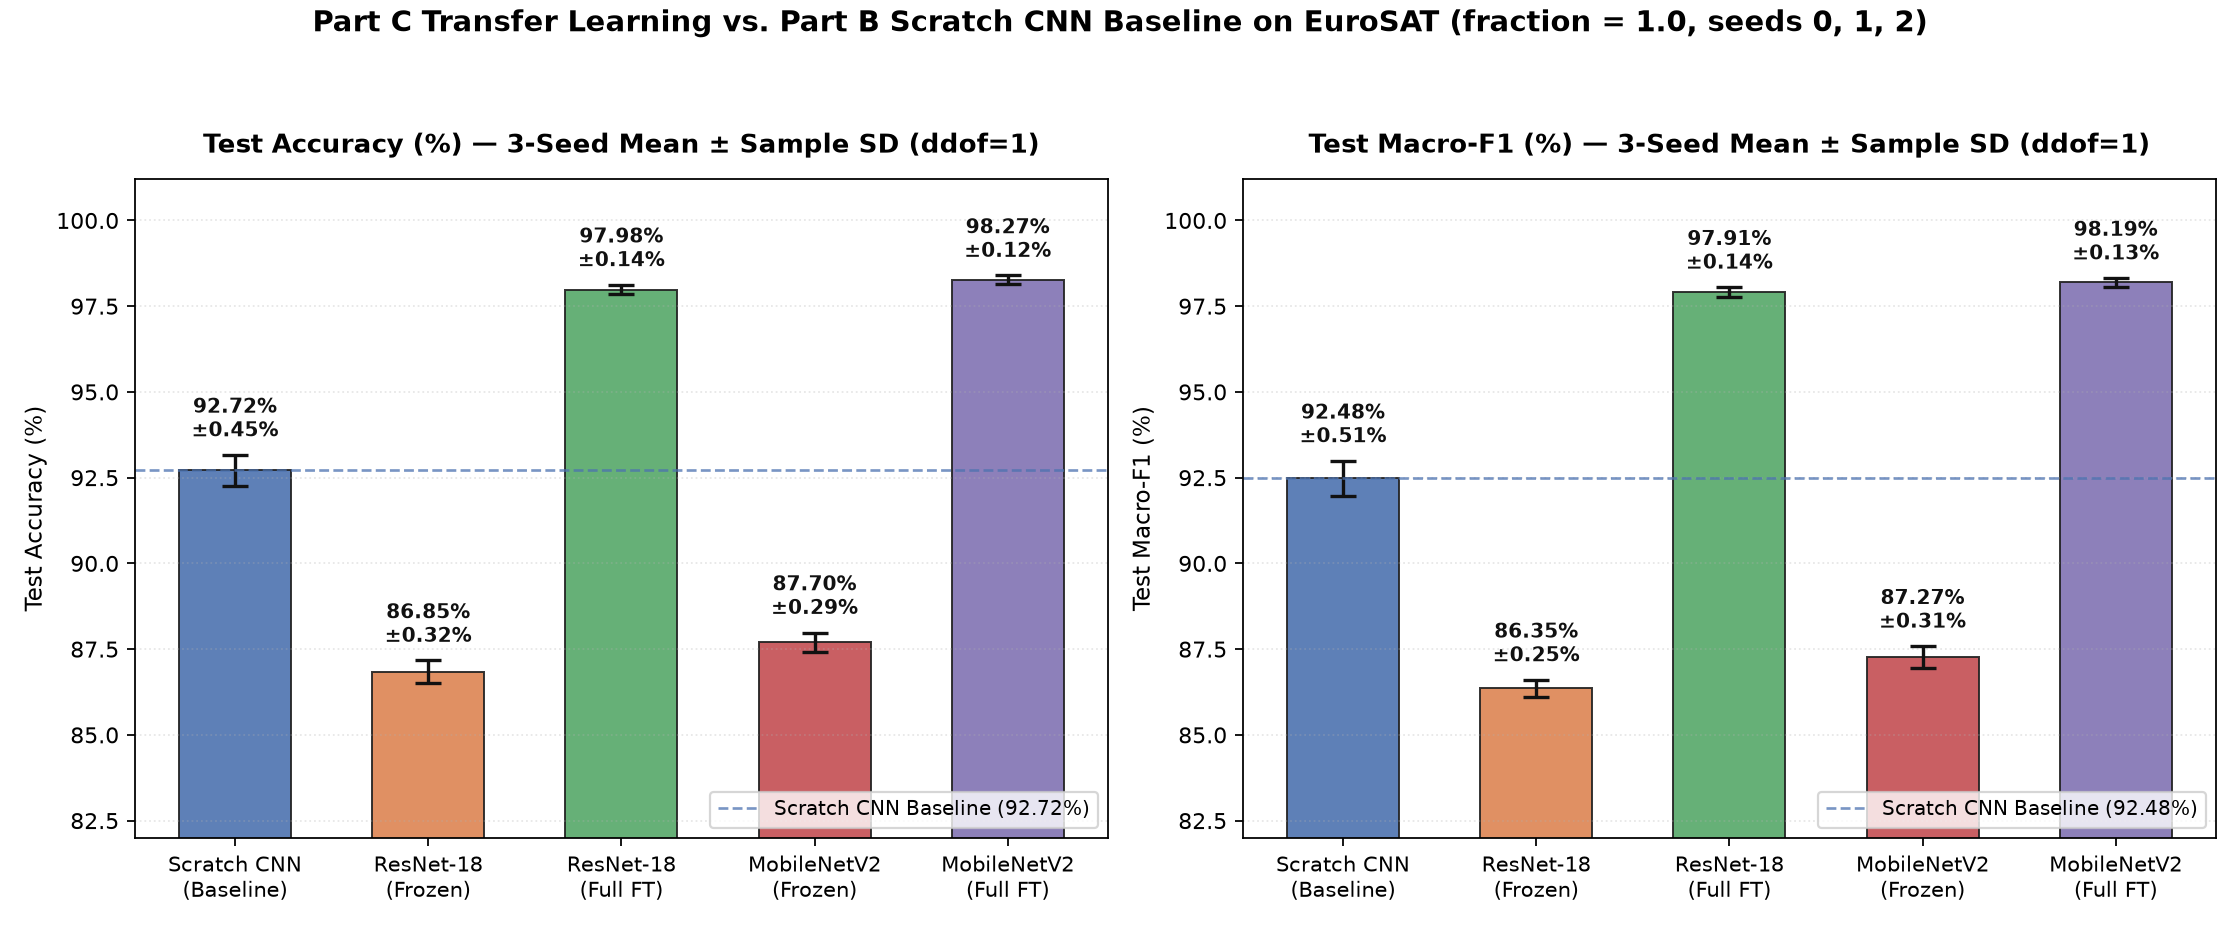

Saved comparison chart to: d:\3rd Year\Deep Learning and CNN\Project\Eyes in the sky\Eyes-in-the-Sky\results\figures\transfer_vs_scratch_comparison.png


In [6]:
# Generate 3-seed comparison bar chart (Mean ± Sample SD, ddof=1) from results/metrics.csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import FIGURES_DIR, METRICS_CSV

df_metrics = pd.read_csv(METRICS_CSV)
models_order = [
    'scratch_cnn',
    'resnet18_frozen',
    'resnet18_full',
    'mobilenet_v2_frozen',
    'mobilenet_v2_full',
]
display_labels = [
    'Scratch CNN\n(Baseline)',
    'ResNet-18\n(Frozen)',
    'ResNet-18\n(Full FT)',
    'MobileNetV2\n(Frozen)',
    'MobileNetV2\n(Full FT)',
]
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']

sub_df = df_metrics[(df_metrics['model'].isin(models_order)) & (df_metrics['fraction'] == 1.0)].copy()
plot_stats = (
    sub_df.groupby('model')
    .agg(
        acc_mean=('accuracy', 'mean'),
        acc_std=('accuracy', lambda s: s.std(ddof=1)),
        f1_mean=('macro_f1', 'mean'),
        f1_std=('macro_f1', lambda s: s.std(ddof=1)),
    )
    .reindex(models_order)
)

acc_means = (plot_stats['acc_mean'] * 100).values
acc_stds = (plot_stats['acc_std'] * 100).values
f1_means = (plot_stats['f1_mean'] * 100).values
f1_stds = (plot_stats['f1_std'] * 100).values

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), dpi=160)
x = np.arange(len(models_order))
bar_width = 0.58

for ax, means, stds, metric_title, ylabel in [
    (axes[0], acc_means, acc_stds, 'Test Accuracy (%) — 3-Seed Mean ± Sample SD (ddof=1)', 'Test Accuracy (%)'),
    (axes[1], f1_means, f1_stds, 'Test Macro-F1 (%) — 3-Seed Mean ± Sample SD (ddof=1)', 'Test Macro-F1 (%)'),
]:
    bars = ax.bar(
        x, means, width=bar_width, yerr=stds, capsize=6,
        color=colors, edgecolor='#222222', linewidth=0.9, alpha=0.90,
        error_kw={'elinewidth': 1.5, 'ecolor': '#111111', 'capthick': 1.5},
    )
    ax.axhline(
        means[0], color='#4C72B0', linestyle='--', linewidth=1.2, alpha=0.75,
        label=f'Scratch CNN Baseline ({means[0]:.2f}%)',
    )
    ax.set_title(metric_title, fontsize=11.5, fontweight='bold', pad=12)
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.set_xticks(x)
    ax.set_xticklabels(display_labels, fontsize=9.5)
    ax.set_ylim(82.0, 101.2)
    ax.grid(axis='y', alpha=0.3, linestyle=':')
    ax.legend(loc='lower right', fontsize=9)
    for bar, m_val, s_val in zip(bars, means, stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            m_val + s_val + 0.35,
            f'{m_val:.2f}%\n±{s_val:.2f}%',
            ha='center', va='bottom', fontsize=8.8, fontweight='bold', color='#111111',
        )

fig.suptitle(
    'Part C Transfer Learning vs. Part B Scratch CNN Baseline on EuroSAT (fraction = 1.0, seeds 0, 1, 2)',
    fontsize=13, fontweight='bold', y=0.99,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
out_fig = FIGURES_DIR / 'transfer_vs_scratch_comparison.png'
plt.savefig(out_fig, dpi=160)
plt.show()
print(f'Saved comparison chart to: {out_fig}')


## 7. Part C Results Analysis, Interpretation, and Limitations

### 7.1 Complete 5-Model Comparison Table (`fraction = 1.0`, `seeds = 0, 1, 2`, Sample SD `ddof=1`)

| Model Configuration | Total Params | Trainable Params | Learning Rate | Seed 0 Acc / F1 (%) | Seed 1 Acc / F1 (%) | Seed 2 Acc / F1 (%) | Test Accuracy (Mean ± Sample SD, %) | Test Macro-F1 (Mean ± Sample SD, %) | Acc Delta vs. Scratch CNN (pp) | Macro-F1 Delta vs. Scratch CNN (pp) |
| :--- | ---: | ---: | ---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| `scratch_cnn` (Part B Baseline) | 93,962 | 93,962 | 0.001 | 93.14 / 92.93 | 92.77 / 92.58 | 92.25 / 91.93 | **92.72% ± 0.45%** | **92.48% ± 0.51%** | — (Baseline) | — (Baseline) |
| `resnet18_frozen` | 11,181,642 | 5,130 | 0.001 | 86.86 / 86.39 | 87.16 / 86.58 | 86.52 / 86.09 | **86.85% ± 0.32%** | **86.35% ± 0.25%** | -5.87 pp | -6.13 pp |
| `resnet18_full` | 11,181,642 | 11,181,642 | 0.0001 | 98.10 / 98.03 | 98.02 / 97.94 | 97.83 / 97.76 | **97.98% ± 0.14%** | **97.91% ± 0.14%** | +5.27 pp | +5.43 pp |
| `mobilenet_v2_frozen` | 2,236,682 | 12,810 | 0.001 | 87.75 / 87.26 | 87.38 / 86.96 | 87.95 / 87.59 | **87.70% ± 0.29%** | **87.27% ± 0.31%** | -5.02 pp | -5.21 pp |
| `mobilenet_v2_full` | 2,236,682 | 2,236,682 | 0.0001 | 98.27 / 98.18 | 98.15 / 98.08 | 98.40 / 98.33 | **98.27% ± 0.12%** | **98.19% ± 0.13%** | +5.56 pp | +5.71 pp |

*(Note: All percentage-point differences are computed from the exact unrounded three-seed means and rounded consistently to two decimal places.)*

---

### 7.2 Answers to the Seven Analytical Questions

1. **Frozen Backbone vs. Full Fine-Tuning Configuration for ResNet-18:**
   - Comparing the two ResNet-18 configurations, the full fine-tuning configuration (`resnet18_full`, `freeze=False`, `lr = 0.0001`) achieves a three-seed mean test accuracy of **97.98% ± 0.14%** compared with **86.85% ± 0.32%** for the frozen-backbone configuration (`resnet18_frozen`, `freeze=True`, `lr = 0.001`)—a performance difference of **+11.14 percentage points** in test accuracy and **+11.56 percentage points** in test macro-F1 (**97.91% ± 0.14%** vs. **86.35% ± 0.25%**).
   - The sample standard deviation (`ddof=1`) across the three seeds is also lower for `resnet18_full` (`0.14%` vs. `0.32%` in accuracy; `0.14%` vs. `0.25%` in macro-F1).
   - **Confounding note:** Because `resnet18_frozen` (`lr = 0.001`) and `resnet18_full` (`lr = 0.0001`) differ in both parameter trainability and learning rate, this `+11.14 pp` difference reflects the combined effect of the two configuration settings rather than unfreezing alone.

2. **Frozen Backbone vs. Full Fine-Tuning Configuration for MobileNetV2:**
   - Comparing the two MobileNetV2 configurations, the full fine-tuning configuration (`mobilenet_v2_full`, `freeze=False`, `lr = 0.0001`) reaches a three-seed mean test accuracy of **98.27% ± 0.12%** compared with **87.70% ± 0.29%** for the frozen-backbone configuration (`mobilenet_v2_frozen`, `freeze=True`, `lr = 0.001`)—a performance difference of **+10.58 percentage points** in test accuracy and **+10.92 percentage points** in test macro-F1 (**98.19% ± 0.13%** vs. **87.27% ± 0.31%**).
   - Just as for ResNet-18, this `+10.58 pp` accuracy difference reflects the comparison between the two complete configurations (`freeze=False, lr=0.0001` vs. `freeze=True, lr=0.001`).

3. **Both Transfer-Learning Architectures vs. the Custom Scratch CNN Baseline (`scratch_cnn`):**
   - **Frozen configurations vs. `scratch_cnn`:** Both frozen-backbone configurations underperform the custom 3-block `scratch_cnn` baseline (**92.72% ± 0.45%** accuracy, **92.48% ± 0.51%** macro-F1). Specifically, `resnet18_frozen` scores **-5.87 percentage points** lower in accuracy (`-6.13 pp` in macro-F1), and `mobilenet_v2_frozen` scores **-5.02 percentage points** lower in accuracy (`-5.21 pp` in macro-F1).
   - **Full fine-tuning configurations vs. `scratch_cnn`:** Conversely, both full fine-tuning configurations outperform `scratch_cnn` by more than 5 percentage points: `resnet18_full` exceeds `scratch_cnn` by **+5.27 percentage points** in accuracy (**+5.43 pp** in macro-F1), and `mobilenet_v2_full` exceeds `scratch_cnn` by **+5.56 percentage points** in accuracy (**+5.71 pp** in macro-F1), reducing the three-seed mean test error rate from **7.28%** (`scratch_cnn`) to **2.02%** (`resnet18_full`) and **1.73%** (`mobilenet_v2_full`).

4. **Does the Small Difference Between `mobilenet_v2_full` and `resnet18_full` Establish Superiority?**
   - **No.** Across our three seeds, `mobilenet_v2_full` (**98.27% ± 0.12%** accuracy, **98.19% ± 0.13%** macro-F1) has a slightly higher three-seed mean than `resnet18_full` (**97.98% ± 0.14%** accuracy, **97.91% ± 0.14%** macro-F1) by **+0.29 percentage points** in accuracy and **+0.28 percentage points** in macro-F1.
   - As an **approximate scale comparison based on the three-seed mean scores** (and not a literal count of unique additional correct test predictions in a single paired run), a difference of `0.2881 percentage points` across `4,050` test images corresponds to roughly `0.002881 × 4,050 ≈ 11.7` (`~12`) test-set predictions on average.
   - Because we evaluated only **$n = 3$ random seeds** on a single fixed data split without formal hypothesis testing or architecture-specific hyperparameter tuning, we **do not claim statistical significance or universal superiority** of MobileNetV2 over ResNet-18. Instead, our results show that **both full fine-tuning configurations achieve comparably strong performance (~98% test accuracy)** on EuroSAT RGB under our team settings, while `mobilenet_v2_full` achieves this with roughly `5×` fewer parameters (`2.24M` vs. `11.18M`).

5. **What Seed-to-Seed Variations Tell Us (and What They Do Not Prove):**
   - Across seeds `0, 1, 2`, the sample standard deviations (`ddof=1`) are small for all five models (`0.12%` to `0.45%` in test accuracy; `0.13%` to `0.51%` in test macro-F1).
   - Because every run uses the **exact same fixed train/val/test split (`data/splits.csv`, generated with `seed = 42`)**, this low seed-to-seed variation shows that convergence is stable across different random weight initialisations of the classification head (or scratch layers), different mini-batch shuffling orders, and different random geometric augmentation draws.
   - **Important distinction:** A small standard deviation across three seeds on a single fixed split **does not prove generalisation across different geographical regions, different satellite capture dates, or independent train/test splits**.

6. **Why ImageNet Features May Transfer to Satellite Imagery and Why Full Fine-Tuning Helps (Distinguishing Evidence, Interpretation, and Untested Factors):**
   - **What our experiments directly demonstrate:**
     - Using frozen ImageNet-pretrained backbone weights with a trained 10-class linear head (`resnet18_frozen` at `86.85%`, `mobilenet_v2_frozen` at `87.70%`) achieves test accuracy well above the `10%` uniform random-guessing level, showing that a linear classifier trained on top of these pretrained representations can correctly classify a large majority of EuroSAT test patches.
     - However, both frozen-backbone configurations perform `5.02` to `5.87 percentage points` *worse* than our compact `scratch_cnn` (`92.72%`), whereas the full fine-tuning configurations (`resnet18_full` at `97.98%`, `mobilenet_v2_full` at `98.27%`, trained at `lr = 0.0001`) achieve `+10.58` to `+11.14 percentage points` higher accuracy than the corresponding frozen configurations and `+5.27` to `+5.56 percentage points` higher accuracy than `scratch_cnn`.
   - **Plausible interpretation based on CNN transfer-learning principles (not a proven causal mechanism from our metrics alone):**
     - Early CNN layers trained on ImageNet typically learn general-purpose visual primitives (edges, colour contrasts, and simple textures) that remain useful in nadir-view satellite imagery, which plausibly explains why training only a linear head on frozen backbone features reaches `~87%`.
     - Conversely, deeper ImageNet layers are tuned to object-centric, ground-level photographs at `224×224` resolution, whereas EuroSAT consists of top-down `64×64` Sentinel-2 patches (`10 m/pixel`) defined by land-cover textures and spatial arrangements. In addition, standard ResNet-18 and MobileNetV2 apply a total spatial stride of `32×`, reducing a `64×64` input to a `2×2` feature map before global average pooling. A plausible interpretation is that keeping the backbone's learnable weights fixed prevents higher-level filters from adapting to overhead spectral-texture patterns and the `64×64` spatial scale, whereas full fine-tuning at a reduced learning rate (`lr = 0.0001`) allows all convolutional layers to adapt to the EuroSAT domain while preserving useful low-level initialization.
   - **Code-verified BatchNorm behaviour in `freeze=True` mode (`src/models.py` & `src/train.py`):**
     - In `src/models.py` (lines 63–66), setting `param.requires_grad = False` freezes all **learnable backbone parameters** (convolutional weights and `BatchNorm2d` affine scale/shift parameters $\gamma, \beta$) so the Adam optimiser updates only the new 10-class linear head.
     - However, in `src/train.py` (line 175), `model.train()` is called on the entire network at the start of each training epoch. In PyTorch, `BatchNorm2d` running statistics (`running_mean` and `running_var`) are registered as non-parameter buffers rather than `nn.Parameter` tensors; therefore, during training epochs, `BatchNorm2d` layers in `resnet18_frozen` and `mobilenet_v2_frozen` normalise batches using current mini-batch statistics and **continue to update their `running_mean` and `running_var` buffers** (and in `mobilenet_v2_frozen`, `model.classifier[0]`'s `Dropout(p=0.2)` remains active during training epochs). Thus, `freeze=True` freezes all learnable backbone weights against gradient updates, rather than locking BatchNorm running buffers in `.eval()` mode.
   - **What remains untested in our study:**
     - Because our frozen (`lr = 0.001`) and full (`lr = 0.0001`) configurations change both backbone parameter trainability and learning rate simultaneously, we did not isolate the effect of learning rate alone. We also did not test layer-wise unfreezing ablations, random-initialisation ResNet-18/MobileNetV2 baselines, freezing `BatchNorm2d` modules in `.eval()` mode during linear probing, or stem-stride / input-resolution (`224×224`) modifications.

7. **Experimental Limitations and Fairness / Provenance Notes:**
   - **Learning-rate and trainability confounding:** As noted above, `freeze=True` (`lr = 0.001`) and `freeze=False` (`lr = 0.0001`) differ in both trainable parameter set and learning rate.
   - **Small number of seeds ($n = 3$):** Three seeds (`0, 1, 2`) are sufficient to check basic training stability, but too small for formal statistical-significance testing between closely matched models.
   - **Single fixed random patch split (`data/splits.csv`):** All runs share one stratified `70/15/15` split (`seed = 42`). Random patch splits in remote sensing can place geographically nearby patches from the same Sentinel-2 swath into both train and test sets (spatial autocorrelation), which may yield higher test accuracy than geographically disjoint splits.
   - **Native `64×64` input resolution with stride-32 backbones:** Passing `64×64` patches directly into unmodified ImageNet backbones yields a `2×2` spatial grid at the final convolutional stage.
   - **RGB bands only:** Only 3 optical bands (`B04, B03, B02`) were used rather than all 13 Sentinel-2 multispectral bands.
   - **Trainer, augmentation-RNG, and hardware provenance across Part B and Part C:**
     - Part B (`02_baseline_cnn.ipynb`) trained `scratch_cnn` using its local `train_one_model` helper (which reads JPEGs from disk via `src/dataset.py`'s `get_loader` and applies per-image PIL/torchvision CPU transforms), whereas Part C trained all 12 transfer runs via Nitin's shared `train()` in `src/train.py` (which caches all `27,000` raw images in memory and applies batch-vectorised GPU rotations/flips). While both trainers share the exact same `data/splits.csv` row indices, ImageNet normalisation constants, `{0°, 90°, 180°, 270°}` rotation + horizontal/vertical flip probabilities, `batch_size = 64`, `Adam(..., foreach=False)`, `CrossEntropyLoss()`, `20` epochs, and validation-accuracy checkpoint rule, their random augmentation draws are not bit-for-bit identical. As documented in `docs/log/nitin.md`, Nitin verified externally that `src/train.py` reproduces Tejash's 3-seed `scratch_cnn` baseline (`92.79%` mean accuracy via `src/train.py` vs. `92.72%` recorded in `results/metrics.csv`).
     - Hardware provenance: Part B (`02_baseline_cnn.ipynb`) and Part C Lap 2 (`seeds 1, 2`) were executed on an `NVIDIA GeForce RTX 3050 6GB Laptop GPU`, while Part C Lap 1 (`seed 0`) was executed on an `NVIDIA GeForce RTX 4050 Laptop GPU`. Furthermore, per-epoch histories for Seeds 1 and 2 in `transfer_all_seeds_histories.json` were recovered from `src/train.py` console logs (`.4f` loss, `.3f` accuracy), whereas all final test accuracy and macro-F1 values in `results/metrics.csv` were saved directly by `src/train.py` at full floating-point precision.